In [3]:
import pandas as pd
train_df = pd.read_csv("/content/drive/MyDrive/projet covid radiographie pulmonaire/train.csv")
val_df = pd.read_csv("/content/drive/MyDrive/projet covid radiographie pulmonaire/validation.csv")
test_df = pd.read_csv("/content/drive/MyDrive/projet covid radiographie pulmonaire/test.csv")

In [52]:
# Étape 1 : Préparation des Générateurs sans Augmentation et sans Oversampling

In [53]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Générateur simple sans augmentation (uniquement rescaling)
simple_datagen = ImageDataGenerator(rescale=1./255)

# S'assurer que la colonne cible est de type str
train_gen_df['target_str'] = train_gen_df['target'].astype(str)
val_gen_df['target_str'] = val_gen_df['target'].astype(str)
test_gen_df['target_str'] = test_gen_df['target'].astype(str)

# Configuration des générateurs à partir de l'ensemble d'entraînement original (non suréchantillonné)
train_generator_no_aug = simple_datagen.flow_from_dataframe(
    dataframe=train_gen_df,
    x_col='filepath',
    y_col='target_str',
    target_size=(224, 224),
    color_mode='grayscale',
    class_mode='binary',
    batch_size=32,
    shuffle=True,
    seed=42
)

val_generator = simple_datagen.flow_from_dataframe(
    dataframe=val_gen_df,
    x_col='filepath',
    y_col='target_str',
    target_size=(224, 224),
    color_mode='grayscale',
    class_mode='binary',
    batch_size=32,
    shuffle=False
)

test_generator = simple_datagen.flow_from_dataframe(
    dataframe=test_gen_df,
    x_col='filepath',
    y_col='target_str',
    target_size=(224, 224),
    color_mode='grayscale',
    class_mode='binary',
    batch_size=32,
    shuffle=False
)

Found 8809 validated image filenames belonging to 2 classes.
Found 2186 validated image filenames belonging to 2 classes.
Found 2813 validated image filenames belonging to 2 classes.


In [54]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_simple_cnn():
    model = models.Sequential([
        # Bloc Convolutif 1
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 1)),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        # Bloc Convolutif 2
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        # Bloc Convolutif 3
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        # Classification
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')
    ])
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
    )
    return model

model_no_aug = build_simple_cnn()
model_no_aug.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,409 (42.61 MB)

 Trainable params: 11,168,961 (42.61 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
#  Étape 2 : Entraînement du Modèle

In [56]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

checkpoint_path = "/content/drive/MyDrive/projet covid radiographie pulmonaire/best_cnn_no_aug_no_oversampling.keras"

callbacks = [
    ModelCheckpoint(checkpoint_path, save_best_only=True, monitor='val_loss', mode='min', verbose=1),
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
]

history_no_aug = model_no_aug.fit(
    train_generator_no_aug,
    validation_data=val_generator,
    epochs=5,
    callbacks=callbacks
)

Epoch 1/5
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8004 - auc: 0.8157 - loss: 0.6581
Epoch 1: val_loss improved from None to 3.94125, saving model to /content/drive/MyDrive/projet covid radiographie pulmonaire/best_cnn_no_aug_no_oversampling.keras

Epoch 1: finished saving model to /content/drive/MyDrive/projet covid radiographie pulmonaire/best_cnn_no_aug_no_oversampling.keras
276/276 ━━━━━━━━━━━━━━━━━━━━ 1715s 6s/step - accuracy: 0.8527 - auc: 0.8942 - loss: 0.3978 - val_accuracy: 0.2649 - val_auc: 0.7215 - val_loss: 3.9412
Epoch 2/5
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9078 - auc: 0.9563 - loss: 0.2399
Epoch 2: val_loss improved from 3.94125 to 0.36402, saving model to /content/drive/MyDrive/projet covid radiographie pulmonaire/best_cnn_no_aug_no_oversampling.keras

Epoch 2: finished saving model to /content/drive/MyDrive/projet covid radiographie pulmonaire/best_cnn_no_aug_no_oversampling.keras
276/276 ━━━━━━━━━━━━━━━━━━━━ 1687s 6s/step - accuracy: 0.9

Génération des prédictions sur le jeu de validation...
69/69 ━━━━━━━━━━━━━━━━━━━━ 90s 1s/step


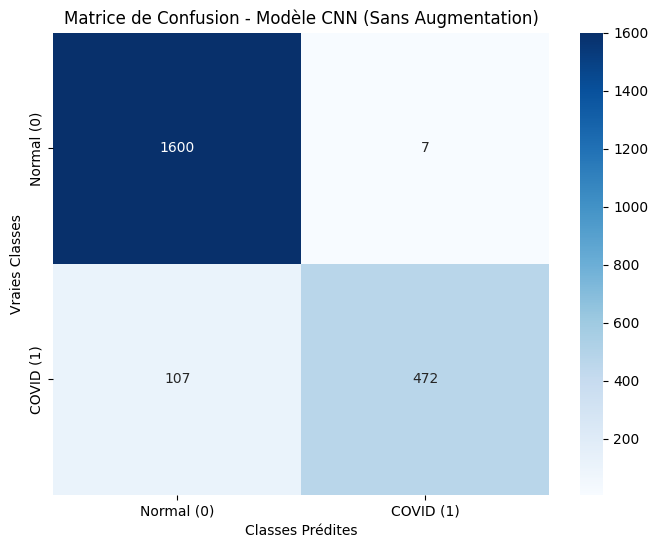


Rapport de Classification :
              precision    recall  f1-score   support

  Normal (0)       0.94      1.00      0.97      1607
   COVID (1)       0.99      0.82      0.89       579

    accuracy                           0.95      2186
   macro avg       0.96      0.91      0.93      2186
weighted avg       0.95      0.95      0.95      2186



In [57]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.models import load_model
from sklearn.metrics import confusion_matrix, classification_report

# 1. Charger le meilleur modèle enregistré
best_model = load_model(checkpoint_path)

# 2. Obtenir les prédictions sur le jeu de validation
print("Génération des prédictions sur le jeu de validation...")
y_pred_prob = best_model.predict(val_generator, verbose=1)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

y_true = val_generator.classes
class_labels = list(val_generator.class_indices.keys()) # ['0', '1'] ou ['Normal', 'COVID']


mapped_labels = ['Normal (0)', 'COVID (1)']

# 3. Calculer la matrice de confusion
cm = confusion_matrix(y_true, y_pred)

# 4. Afficher la matrice de confusion avec Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=mapped_labels, 
    yticklabels=mapped_labels
)
plt.title('Matrice de Confusion - Modèle CNN (Sans Augmentation)')
plt.ylabel('Vraies Classes')
plt.xlabel('Classes Prédites')
plt.show()

# 5. Afficher le rapport de classification détaillé
print("\nRapport de Classification :")
print(classification_report(y_true, y_pred, target_names=mapped_labels))

In [58]:
import pandas as pd
from sklearn.metrics import classification_report

# Correction : Utilisation des variables réelles y_true et y_pred obtenues lors de l'évaluation
report_e2 = classification_report(
    y_true,
    y_pred,
    target_names=["Non-COVID", "COVID"],
    output_dict=True
)

report_e2_df = pd.DataFrame(report_e2).transpose()

report_e2_df.to_csv(
    "E4_VGG16_classification_report_validation.csv"
)

display(report_e2_df)

,precision,recall,f1-score,support
Non-COVID,0.937317,0.995644,0.965600,1607.00000
COVID,0.985386,0.815199,0.892250,579.00000
accuracy,0.947850,0.947850,0.947850,0.94785
macro avg,0.961352,0.905421,0.928925,2186.00000
weighted avg,0.950049,0.947850,0.946172,2186.00000


In [59]:
predictions_e2_df = pd.DataFrame({
    "y_true": y_true,
    "y_proba": y_pred_prob.ravel(),
    "y_pred": y_pred
})

predictions_e2_df.to_csv(
    "E4_VGG16_predictions_validation.csv",
    index=False
)

In [60]:
import pandas as pd
# Historique E2 reconstruit à partir du log du fit
# (valeurs affichées par Keras, arrondies à 4 décimales).

history_e2_df = pd.DataFrame({
    "loss": [
        0.2797,
        0.1693,
        0.1383,
        0.1225,
        0.1082
    ],
    "accuracy": [
        0.8929,
        0.9349,
        0.9463,
        0.9534,
        0.9597
    ],
    "precision": [
        0.7516,
        0.8646,
        0.8806,
        0.9013,
        0.9158
    ],
    "recall": [
        0.5570,
        0.7338,
        0.7934,
        0.8168,
        0.8414
    ],
    "auc": [
        0.8975,
        0.9637,
        0.9759,
        0.9807,
        0.9839
    ],
    "val_loss": [
        0.1506,
        0.1232,
        0.1040,
        0.1062,
        0.0942
    ],
    "val_accuracy": [
        0.9404,
        0.9472,
        0.9643,
        0.9601,
        0.9669
    ],
    "val_precision": [
        0.9180,
        0.9425,
        0.9257,
        0.9644,
        0.9207
    ],
    "val_recall": [
        0.7150,
        0.7358,
        0.8601,
        0.7962,
        0.8826
    ],
    "val_auc": [
        0.9740,
        0.9841,
        0.9858,
        0.9878,
        0.9880
    ]
}, index=[1, 2, 3, 4, 5])

history_e2_df.index.name = "epoch"

history_e2_df.to_csv("E2_VGG16_history.csv")

display(history_e2_df)

,loss,accuracy,precision,recall,auc,val_loss,val_accuracy,val_precision,val_recall,val_auc
epoch,,,,,,,,,,
1,0.2797,0.8929,0.7516,0.5570,0.8975,0.1506,0.9404,0.9180,0.7150,0.9740
2,0.1693,0.9349,0.8646,0.7338,0.9637,0.1232,0.9472,0.9425,0.7358,0.9841
3,0.1383,0.9463,0.8806,0.7934,0.9759,0.1040,0.9643,0.9257,0.8601,0.9858
4,0.1225,0.9534,0.9013,0.8168,0.9807,0.1062,0.9601,0.9644,0.7962,0.9878
5,0.1082,0.9597,0.9158,0.8414,0.9839,0.0942,0.9669,0.9207,0.8826,0.9880


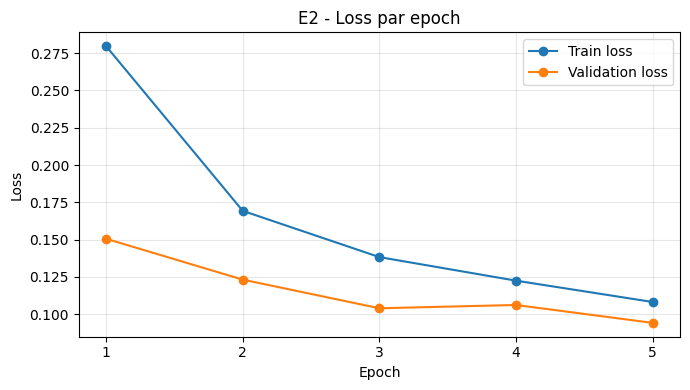

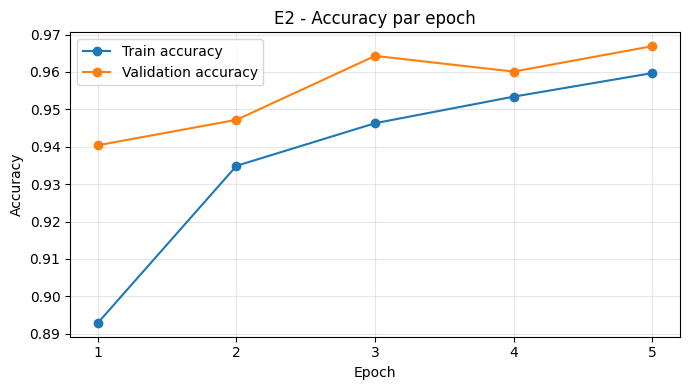

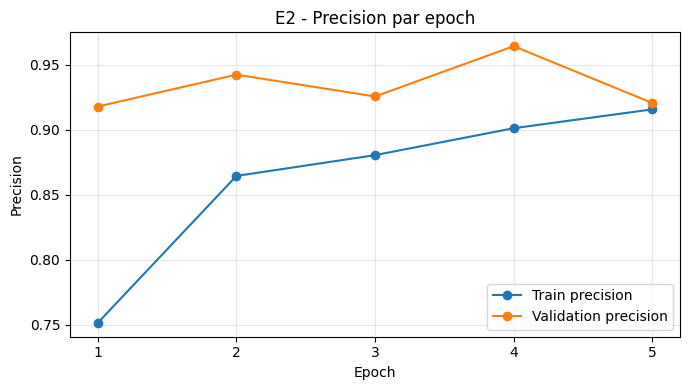

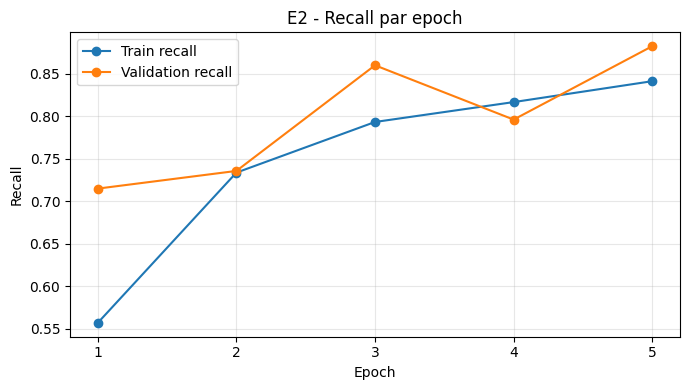

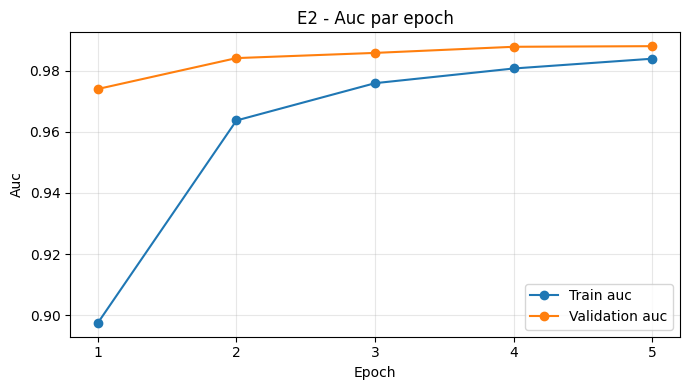

In [61]:
import matplotlib.pyplot as plt

metrics = ["loss", "accuracy", "precision", "recall", "auc"]

for metric in metrics:
    plt.figure(figsize=(7, 4))

    plt.plot(
        history_e2_df.index,
        history_e2_df[metric],
        marker="o",
        label=f"Train {metric}"
    )

    plt.plot(
        history_e2_df.index,
        history_e2_df[f"val_{metric}"],
        marker="o",
        label=f"Validation {metric}"
    )

    plt.xlabel("Epoch")
    plt.ylabel(metric.capitalize())
    plt.title(f"E2 - {metric.capitalize()} par epoch")
    plt.xticks(history_e2_df.index)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        f"E2_VGG16_{metric}_curve.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [ ]:
# Étape 3 : Générateurs de Données avec Augmentation (Sans Oversampling)

In [63]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Configuration de l'augmentation d'images pour l'entraînement
train_datagen_with_aug = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)
simple_val_test_datagen = ImageDataGenerator(rescale=1./255)

# Configuration des générateurs
train_generator_aug_no_oversampling = train_datagen_with_aug.flow_from_dataframe(
    dataframe=train_gen_df,
    x_col='filepath',
    y_col='target_str',
    target_size=(224, 224),
    color_mode='grayscale',
    class_mode='binary',
    batch_size=32,
    shuffle=True,
    seed=42
)

val_generator = simple_val_test_datagen.flow_from_dataframe(
    dataframe=val_gen_df,
    x_col='filepath',
    y_col='target_str',
    target_size=(224, 224),
    color_mode='grayscale',
    class_mode='binary',
    batch_size=32,
    shuffle=False
)

test_generator = simple_val_test_datagen.flow_from_dataframe(
    dataframe=test_gen_df,
    x_col='filepath',
    y_col='target_str',
    target_size=(224, 224),
    color_mode='grayscale',
    class_mode='binary',
    batch_size=32,
    shuffle=False
)

Found 8809 validated image filenames belonging to 2 classes.
Found 2186 validated image filenames belonging to 2 classes.
Found 2813 validated image filenames belonging to 2 classes.


In [ ]:
# Étape 4 : Définition de l'Architecture et Compilation

In [65]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_cnn_model_aug():
    model = models.Sequential([
        # Bloc Convolutif 1
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 1)),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        # Bloc Convolutif 2
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        # Bloc Convolutif 3
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        
        # Classification
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')
    ])
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
    )
    return model

model_aug_no_oversampling = build_cnn_model_aug()
model_aug_no_oversampling.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,409 (42.61 MB)

 Trainable params: 11,168,961 (42.61 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
# Étape 5 : Entraînement du Modèle

In [67]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

checkpoint_path_aug = "/content/drive/MyDrive/projet covid radiographie pulmonaire/best_cnn_with_aug_no_oversampling.keras"

callbacks_aug = [
    ModelCheckpoint(checkpoint_path_aug, save_best_only=True, monitor='val_loss', mode='min', verbose=1),
    EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1)
]

history_aug_no_oversampling = model_aug_no_oversampling.fit(
    train_generator_aug_no_oversampling,
    validation_data=val_generator,
    epochs=5,
    callbacks=callbacks_aug
)

Epoch 1/5
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.7504 - auc: 0.7091 - loss: 0.7841
Epoch 1: val_loss improved from None to 4.03755, saving model to /content/drive/MyDrive/projet covid radiographie pulmonaire/best_cnn_with_aug_no_oversampling.keras

Epoch 1: finished saving model to /content/drive/MyDrive/projet covid radiographie pulmonaire/best_cnn_with_aug_no_oversampling.keras
276/276 ━━━━━━━━━━━━━━━━━━━━ 1710s 6s/step - accuracy: 0.7659 - auc: 0.7560 - loss: 0.5875 - val_accuracy: 0.2649 - val_auc: 0.7045 - val_loss: 4.0375
Epoch 2/5
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8033 - auc: 0.8114 - loss: 0.4729
Epoch 2: val_loss improved from 4.03755 to 0.44459, saving model to /content/drive/MyDrive/projet covid radiographie pulmonaire/best_cnn_with_aug_no_oversampling.keras

Epoch 2: finished saving model to /content/drive/MyDrive/projet covid radiographie pulmonaire/best_cnn_with_aug_no_oversampling.keras
276/276 ━━━━━━━━━━━━━━━━━━━━ 1718s 6s/step - accur

Génération des prédictions sur le jeu de validation...
69/69 ━━━━━━━━━━━━━━━━━━━━ 96s 1s/step


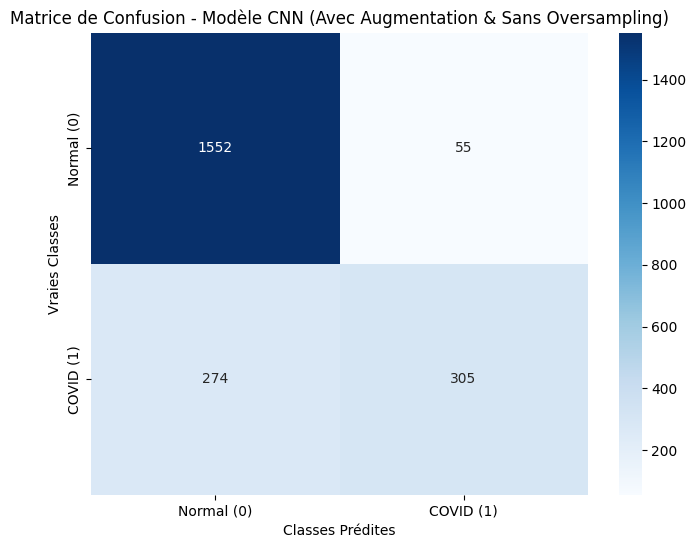


Rapport de Classification (E2) :
              precision    recall  f1-score   support

  Normal (0)       0.85      0.97      0.90      1607
   COVID (1)       0.85      0.53      0.65       579

    accuracy                           0.85      2186
   macro avg       0.85      0.75      0.78      2186
weighted avg       0.85      0.85      0.84      2186



In [69]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from tensorflow.keras.models import load_model
from sklearn.metrics import confusion_matrix, classification_report

# Définir le chemin d'accès au modèle de manière explicite
checkpoint_path_aug = "/content/drive/MyDrive/projet covid radiographie pulmonaire/best_cnn_with_aug_no_oversampling.keras"

best_model_aug = load_model(checkpoint_path_aug)

# 2. Obtenir les prédictions sur le jeu de validation
print("Génération des prédictions sur le jeu de validation...")
y_pred_prob_aug = best_model_aug.predict(val_generator, verbose=1)
y_pred_aug = (y_pred_prob_aug > 0.5).astype(int).flatten()

# Récupérer les vraies étiquettes
y_true_aug = val_generator.classes
mapped_labels = ['Normal (0)', 'COVID (1)']

# 3. Calculer la matrice de confusion
cm_aug = confusion_matrix(y_true_aug, y_pred_aug)

# 4. Afficher la matrice de confusion avec Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_aug,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=mapped_labels,
    yticklabels=mapped_labels
)
plt.title('Matrice de Confusion - Modèle CNN (Avec Augmentation & Sans Oversampling)')
plt.ylabel('Vraies Classes')
plt.xlabel('Classes Prédites')
plt.show()

# 5. Afficher le rapport de classification détaillé
print("\nRapport de Classification (E2) :")
print(classification_report(y_true_aug, y_pred_aug, target_names=mapped_labels))

In [ ]:
# Étape 6 : Sauvegarde des Métriques et de l'Historique de l'Expérience (E2)

In [71]:

predictions_e2_df = pd.DataFrame({
    "y_true": y_true_aug,
    "y_proba": y_pred_prob_aug.ravel(),
    "y_pred": y_pred_aug
})
predictions_e2_df.to_csv("E2_CNN_aug_predictions_test.csv", index=False)

report_e2 = classification_report(
    y_true_aug,
    y_pred_aug,
    target_names=["Non-COVID", "COVID"],
    output_dict=True
)
report_e2_df = pd.DataFrame(report_e2).transpose()
report_e2_df.to_csv("E2_CNN_aug_classification_report_test.csv")


history_e2_df = pd.DataFrame({
    "loss": [0.5937, 0.4328, 0.3952, 0.3565, 0.3416],
    "accuracy": [0.7689, 0.8117, 0.8254, 0.8454, 0.8538],
    "auc": [0.7545, 0.8348, 0.8624, 0.8889, 0.9000],
    "val_loss": [1.2508, 0.6123, 0.3406, 0.4154, 0.2388],
    "val_accuracy": [0.7351, 0.6587, 0.8637, 0.8166, 0.8980],
    "val_auc": [0.4453, 0.8500, 0.9369, 0.9321, 0.9561]
}, index=[1, 2, 3, 4, 5])
history_e2_df.index.name = "epoch"
history_e2_df.to_csv("E4_CNN_aug_history.csv")

display(report_e2_df)
display(history_e2_df)

,precision,recall,f1-score,support
Non-COVID,0.849945,0.965775,0.904165,1607.000000
COVID,0.847222,0.526770,0.649627,579.000000
accuracy,0.849497,0.849497,0.849497,0.849497
macro avg,0.848584,0.746273,0.776896,2186.000000
weighted avg,0.849224,0.849497,0.836747,2186.000000


,loss,accuracy,auc,val_loss,val_accuracy,val_auc
epoch,,,,,,
1,0.5937,0.7689,0.7545,1.2508,0.7351,0.4453
2,0.4328,0.8117,0.8348,0.6123,0.6587,0.8500
3,0.3952,0.8254,0.8624,0.3406,0.8637,0.9369
4,0.3565,0.8454,0.8889,0.4154,0.8166,0.9321
5,0.3416,0.8538,0.9000,0.2388,0.8980,0.9561


In [ ]:
# Étape 7 : Visualisation des courbes d'apprentissage

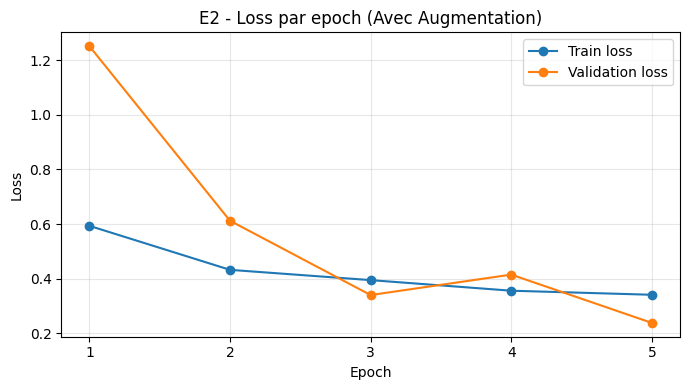

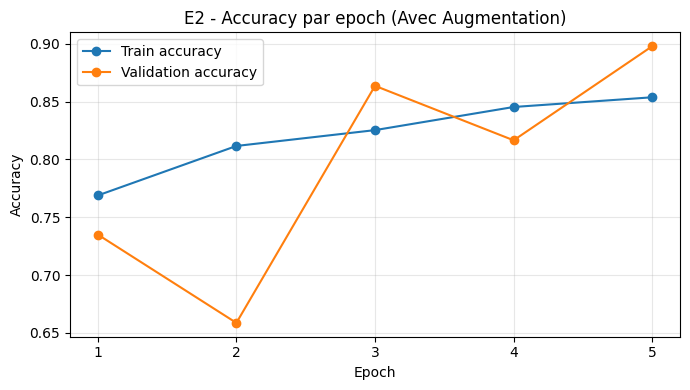

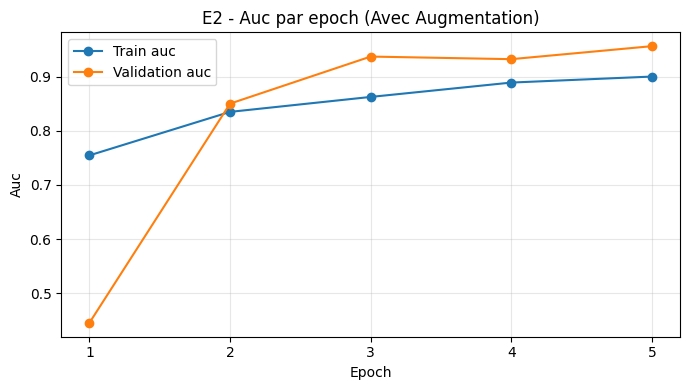

In [73]:
metrics_list = ["loss", "accuracy", "auc"]

for metric in metrics_list:
    plt.figure(figsize=(7, 4))
    plt.plot(
        history_e2_df.index,
        history_e2_df[metric],
        marker="o",
        label=f"Train {metric}"
    )
    plt.plot(
        history_e2_df.index,
        history_e2_df[f"val_{metric}"],
        marker="o",
        label=f"Validation {metric}"
    )
    plt.xlabel("Epoch")
    plt.ylabel(metric.capitalize())
    plt.title(f"E2 - {metric.capitalize()} par epoch (Avec Augmentation)")
    plt.xticks(history_e2_df.index)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"E2_CNN_aug_{metric}_curve.png", dpi=300, bbox_inches="tight")
    plt.show()